<center>
    <h2>Master 2</h2>
    <h5 style="margin-top: 5px">Sciences de l’Océan, de l’Atmosphère et du Climat</h5>
    <h1>TP - Système climatique</h1>
  <br>
    <strong>Contact:</strong> isaline.bossert@meteo.fr / romain.torres4@gmail.com

</center>


<div style="padding: 1rem; background-color: #d1ecf1; border: 1px solid #bee5eb; border-radius: 4px; margin: 1rem 0;">
  <strong>💡 Instructions</strong> 
    
Ce notebook est à <i>compléter</i> avec vos réponses aux questions posées et à <i>envoyer</i> par mail au plus tard <u>une semaine après la dernière séance de TP</u>. Merci de renommer le notebook pour y incorporer vos noms de famille (ex: TP-Climat-2026-Nom1_Nom2_Nom3.ipynb)
  - une attention particulière doit être donnée aux <b>figures</b> (clareté, titre, axes, légendes, etc..) 
  - les analyses portent sur vos <b>connaissances théoriques</b> en lien avec le cours "Système Climatique" (J. Cattiaux) sont attendues
  - la <b>curiosité scientifique</b> est bien sûre encouragée: même si les questions sont là pour aiguiller le TP, n'hésitez pas à demander des clarifications où d'éventuelles pistes d'analyses supplémentaires ;)
    

⚠️ Lors de la dernière séance, chaque groupe présentera son notebook (sujet + analyses effectuées):
  - durée max de 12 minutes de restitution qui doit être <b>claire</b> et <b>synthétique</b>. Il n'est pas nécessaire de créer un support de présentation particulier.
  - la restitution est suivie d'un <b>tour de questions</b> de la part des élèves puis des enseignantes pour vérifier les notions

<center>
        <h1>Sujet 3: Towards global climate stabilization, the use of emission-driven configurations </h1>
  <br>
    <strong>Main topics covered here:</strong>
    <br>
    Climate equilibration (c.f. Cours 1)
    <br>

</center>

## Introduction

A la différence des autres TPs ici on va commencer par comprendre comment mettre en place un protocol expérimental précis afin de répondre à des questions scientifiques.
The aim of this TP is to understand how to build idealized simulation. For that we place ourself in a specific context : 

- Contexte du chgt climatique et de la nécéssité de stopper nos émissions : paris agreement. Se questionner sur des possibilités de réversibilité (ou non) dans le cas d'émissions négatives
- Contexte de emission driven


<div align="center">
    <div id="tp1-fig1" style="width: 550px; float: left">
        <img src="../figures/Ch3_framework_jones.png" alt="drawing" width="400"\>
        

- Contexte de faire un protocol expérimental clair pour être reproductible par de nombreux centres de recherche en climat afin de réaliser des études multimodèles.

<b>TIPMIP protocol </b> [(Jones et al., 2026)](https://gmd.copernicus.org/articles/19/6941/2026/):

The TIPMIP protocol is composed of five types of simulations:
- 1 piControl run (black)
- 1 net-positive ramp-up run (red)
- 2 net-zero runs (dark green)
- 2 net-negative ramp-down (blue)
- 1 net-zero run following a ramp-down phase (light green)

All of these simulations are shown as schematics in the figure below where the x-axis represents the model years and the y-axis represents the Global Mean Surface Temperature (GSAT).

<div align="center">
    <div id="tp1-fig1" style="width: 550px; float: left">
        <img src="../figures/gmd-19-6941-2026-avatar-web.png" alt="drawing" width="700"\>
        
        
The aim of the protocol is to build (in a coordinated manner) a ramp-up run which branches from a piControl run. This ramp-up phase must create an increase in GSAT of about 0.2°C/decade. Next, CO$_2$ emissions are shut down when the ramp-up GSAT reaches specific Global Warming Levels (GWLs). 

        
In particular, you will:
  - work with 2D data but also timeseries
  - Discover a different modelling configuration than in the other TP subjects
  
This work is based on a bunch of simulation that you will discover throughout the TP


For a bit of undestanding : GSAT (global surface air temperature)

On va partir d'un piControl run et construire notre compréhension de processus physique au fur est mesure du TP

Intérêt des scénarios en mode émission


## Load Python modules and simulation outputs

Along this notebook, Python codes are used to analyse model outputs.
You first need to import and load required modules:

In [131]:
# manipulate file and data
import xarray as xr
import pandas as pd
# statistics package


# plotting
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cmocean

In [177]:
# csv
df_GSAT = pd.read_csv("./../data/CNRM-ESM2-2/dataframe_02Kpd_timeseries_yearly_tas.csv")
df_GSAT2 = pd.read_csv("./../data/CNRM-ESM2-2/dataframe_GSAT_CNRM-ESM2-2.csv")
df_CO2 = pd.read_csv("./../data/CNRM-ESM2-2/dataframe_02Kpd_timeseries_yearly_co2s.csv")

# netcdf
areacella = xr.open_dataset("./../data/CNRM-ESM2-2/areacella_CNRM-ESM2-1.nc")
ym_tas_11 = xr.open_dataset("./../data/CNRM-ESM2-2/tas_Ayr_CNRM-ESM2-1_02Kpd-11_r1i1p2f2_gr_190201-220112.nc")
ym_tas = xr.open_dataset("./../data/CNRM-ESM2-2/tas_Ayr_CNRM-ESM2-1_02Kpd_r1i1p2f2_gr_185001-214912.nc")

<a id="section-1"></a>
## 1. Technical aspects

In the world of climate science, we use a different bunch of files. Among them are .csv files and netcdf files. The former are quite useful when working with timeseries while the latter are useful when working with 2D+time of 3D+time data.

Post-treatment of model output is a great part of the work of a climate scientist. 

df = pd.read_csv("")
then you can access the data by selecting the columns. For example the first column can be accessed via df["year"]


On the other hand we have netcdf. These can be opened in python using the xarray package. This package contains a lot of functions which enables the analysis of the netcdf.
Informations are given via dimensions, coordinates variables and attributes etc.

For example you can calculate a mean by using the function .mean() from which you should state the dimension over which to calculate it. See the xarray documentation : https://docs.xarray.dev/en/stable/generated/xarray.DataArray.mean.html


In [178]:
df_GSAT

,year,piControl,02Kpd,02Kpd-11,02Kpd-15,02Kpd-20,02Kpd-25,02Kpd-30,02Kpd-35,02Kpd-40,02Kpd-45,02Kpd-50
0,1850,13.550171,13.550446,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1851,13.561768,13.637268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1852,13.799713,13.671295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1853,13.622833,13.645660,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1854,13.690948,13.792664,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
532,2382,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.388550
533,2383,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.501251
534,2384,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.402496
535,2385,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.452667


In [179]:
ym_tas_11

<xarray.Dataset>
Dimensions:    (time: 300, bnds: 2, lon: 256, lat: 128)
Coordinates:
  * time       (time) datetime64[ns] 1902-07-01T06:00:00 ... 2201-07-01T06:00:00
  * lon        (lon) float64 0.0 1.406 2.812 4.219 ... 354.4 355.8 357.2 358.6
  * lat        (lat) float64 -88.93 -87.54 -86.14 -84.74 ... 86.14 87.54 88.93
    height     float64 ...
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] ...
    tas        (time, lat, lon) float32 ...
Attributes: (12/54)
    CDI:                    Climate Data Interface version 2.0.4 (https://mpi...
    source:                 CNRM-ESM2-1 (2017):  aerosol: TACTIC_v2 atmos: Ar...
    institution:            CNRM (Centre National de Recherches Meteorologiqu...
    Conventions:            CF-1.7 CMIP-6.2
    name:                   /scratch/work/bosserti/CMIP6/DECK/AOESM_02Kpd-11_...
    description:            Created by xios
    ...                     ...
    dr2xml_md5sum:          9a1fa5cac842f55652e42ad1d6b59c62
    xios_commit:            1442-shuffle
    nemo_gelato_commit:     49095b3accd5d4c_6524fe19b00467a
    arpege_minor_version:   6.3.2
    tracking_id:            hdl:21.14100/6f380031-4877-4380-bb93-809cab69742d
    CDO:                    Climate Data Operators version 2.0.4 (https://mpi...

Calculate TCRE OF the model ??
give the TCRE for other model and infer the timeseries for GSAT for all model and compare with modeling experiment of other modeling groups

<a id="section-1"></a>
## 1.Building the ramp-up simulation



The aim here is to first calculate the TCRE. Transient Climate Response to Cumulative Emission.

1pctCO2 simulation

<div align="center">
    <div id="tp1-fig1" style="width: 10; float: left">
        <img src="../figures/Ch3_1pctco2_abrupt4xco2.png" alt="drawing" width="300"\>
        


<a id="section-1"></a>
## 1. Global scale metrics behaviour - Getting started with climate data

In this section, we will first analyse the behaviour of global scale metrics following emission cessation.

#### Question 1: 

* First lets investigate the behaviour of GSAT and GMCO2 in the picontrol run

Text(0.5, 1.0, 'b. GMCO2 in piControl')

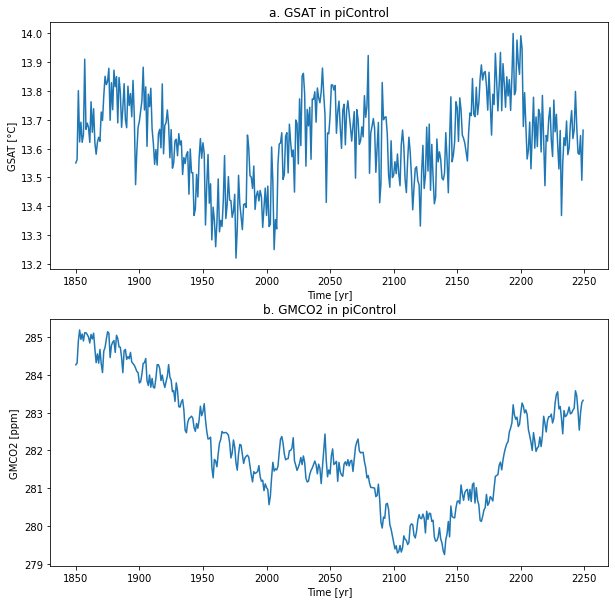

In [180]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

axes[0].plot(df_GSAT["year"], df_GSAT["piControl"])
axes[1].plot(df_CO2["year"], df_CO2["piControl"])

axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in piControl")
axes[1].set_title("b. GMCO2 in piControl")

#### Question 2: 

In climate science, when working with model outputs, we often work with anomalies with respect to a baseline and not with absolute data. This enables scientists to compare models that differ slightly.

* _Plot GMCO2 and GSAT in anomalies_
* _Discuss the behaviour of the model in these piControl runs. Calcule the temporal mean and the trend._

Text(0.5, 1.0, 'b. GMCO2 in piControl')

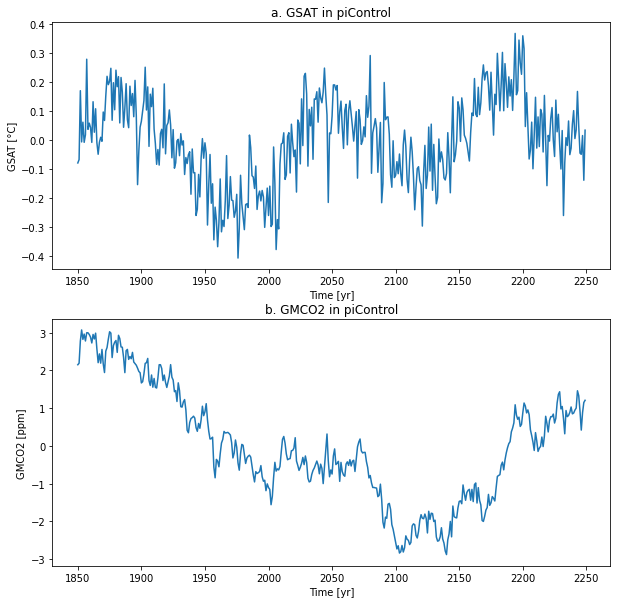

In [181]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

axes[0].plot(df_GSAT["year"], df_GSAT["piControl"]-df_GSAT["piControl"].mean())
axes[1].plot(df_CO2["year"], df_CO2["piControl"]-df_CO2["piControl"].mean())

axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in piControl")
axes[1].set_title("b. GMCO2 in piControl")

INSIGHT SUR LA TCRE metrique clef et donc il faut que les élèves prédisent la shape du ramp-up !!

#### Question 2: 

Now we will add another simulation which was started from the piControl
* _Plot GSAT and GMCO2 of the 02Kpd run on top of the piControl run"_
* _What can you infer on the forcing of our model ? Describe GSAT behaviour "_

Text(0.5, 1.0, 'b. GMCO2 in piControl')

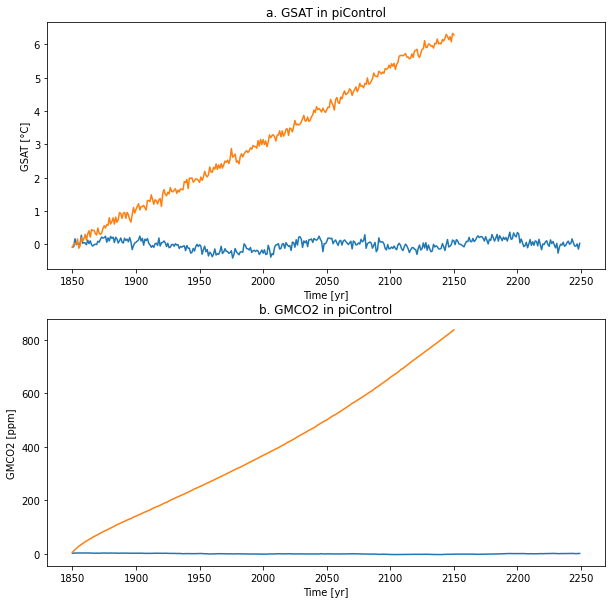

In [182]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

ref_CO2 = df_CO2["piControl"].mean()
ref_GSAT = df_GSAT["piControl"].mean()

axes[0].plot(df_GSAT["year"], df_GSAT["piControl"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["piControl"]-ref_CO2)

axes[0].plot(df_GSAT["year"], df_GSAT["02Kpd"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["02Kpd"]-ref_CO2)

axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in piControl")
axes[1].set_title("b. GMCO2 in piControl")

#### Question 3: 

Lets move on to the next simulation. 
* _Plot GSAT and GMCO2 for simulation 02Kpd-11"_
* _According to you what changes were made in the forcings to obtain this new simulation ?_

In [183]:
ym_tas_11.mean(["lat", "lon"])

<xarray.Dataset>
Dimensions:    (time: 300, bnds: 2)
Coordinates:
  * time       (time) datetime64[ns] 1902-07-01T06:00:00 ... 2201-07-01T06:00:00
    height     float64 ...
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 1902-01-01 1903-01-01 ... 2202-01-01
    tas        (time) float32 279.1 279.0 279.2 279.2 ... 278.9 279.1 278.9

In [184]:
ym_tas_11["time"]

<xarray.DataArray 'time' (time: 300)>
array(['1902-07-01T06:00:00.000000000', '1903-07-01T06:00:00.000000000',
       '1904-07-01T06:00:00.000000000', ..., '2199-07-01T06:00:00.000000000',
       '2200-07-01T06:00:00.000000000', '2201-07-01T06:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 1902-07-01T06:00:00 ... 2201-07-01T06:00:00
    height   float64 ...
Attributes:
    standard_name:  time
    long_name:      Time axis
    bounds:         time_bnds
    axis:           T

Text(0.5, 1.0, 'b. GMCO2 in piControl')

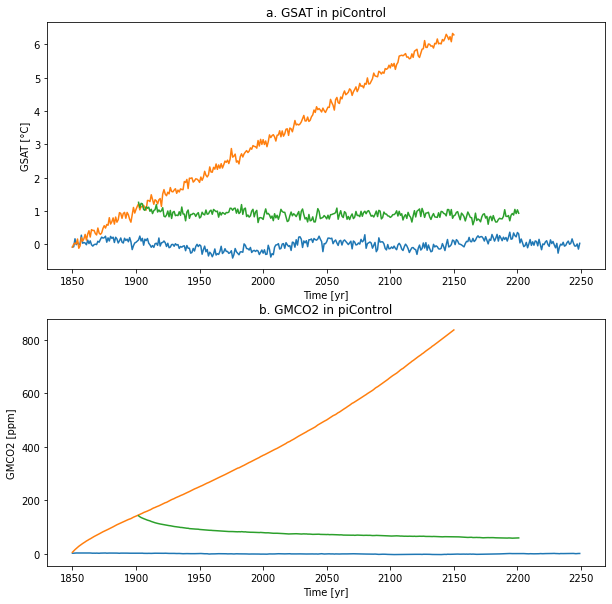

In [185]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

ref_CO2 = df_CO2["piControl"].mean()
ref_GSAT = df_GSAT["piControl"].mean()

axes[0].plot(df_GSAT["year"], df_GSAT["piControl"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["piControl"]-ref_CO2)

axes[0].plot(df_GSAT["year"], df_GSAT["02Kpd"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["02Kpd"]-ref_CO2)

axes[0].plot(df_GSAT["year"], df_GSAT["02Kpd-11"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["02Kpd-11"]-ref_CO2)


axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in piControl")
axes[1].set_title("b. GMCO2 in piControl")

In [186]:
ym_tas_11

<xarray.Dataset>
Dimensions:    (time: 300, bnds: 2, lon: 256, lat: 128)
Coordinates:
  * time       (time) datetime64[ns] 1902-07-01T06:00:00 ... 2201-07-01T06:00:00
  * lon        (lon) float64 0.0 1.406 2.812 4.219 ... 354.4 355.8 357.2 358.6
  * lat        (lat) float64 -88.93 -87.54 -86.14 -84.74 ... 86.14 87.54 88.93
    height     float64 ...
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 1902-01-01 1903-01-01 ... 2202-01-01
    tas        (time, lat, lon) float32 226.3 226.3 226.3 ... 255.1 255.1 255.1
Attributes: (12/54)
    CDI:                    Climate Data Interface version 2.0.4 (https://mpi...
    source:                 CNRM-ESM2-1 (2017):  aerosol: TACTIC_v2 atmos: Ar...
    institution:            CNRM (Centre National de Recherches Meteorologiqu...
    Conventions:            CF-1.7 CMIP-6.2
    name:                   /scratch/work/bosserti/CMIP6/DECK/AOESM_02Kpd-11_...
    description:            Created by xios
    ...                     ...
    dr2xml_md5sum:          9a1fa5cac842f55652e42ad1d6b59c62
    xios_commit:            1442-shuffle
    nemo_gelato_commit:     49095b3accd5d4c_6524fe19b00467a
    arpege_minor_version:   6.3.2
    tracking_id:            hdl:21.14100/6f380031-4877-4380-bb93-809cab69742d
    CDO:                    Climate Data Operators version 2.0.4 (https://mpi...

#### Question 3: 

Okay, now we will plot a lot of simulations : 
    
* _Plot the rest of the simulations in the dataframes df_CO2 and df_GSAT. Use a for-loop and use meaningful colors for each of the runs._
* _Characterize the behaviour of GSAT_

piControl
02Kpd
02Kpd-11
02Kpd-15
02Kpd-20
02Kpd-25
02Kpd-30
02Kpd-35
02Kpd-40
02Kpd-45
02Kpd-50


Text(0.5, 1.0, 'b. GMCO2 in piControl')

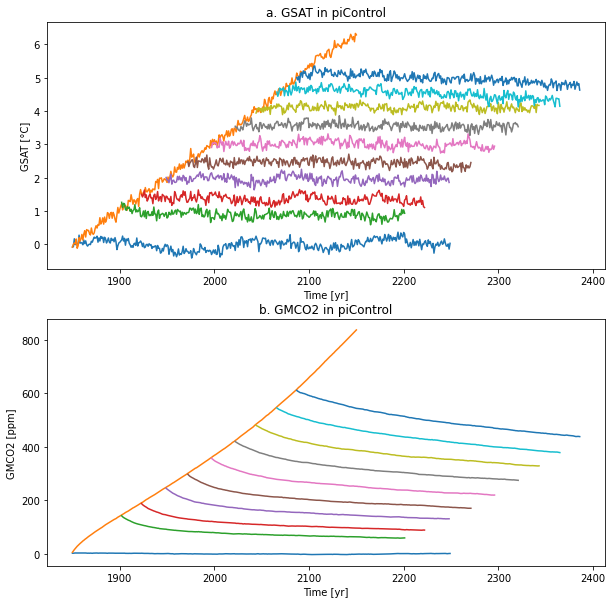

In [187]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

ref_CO2 = df_CO2["piControl"].mean()
ref_GSAT = df_GSAT["piControl"].mean()

columns = df_GSAT.keys()
for i in range(1,len(columns)):
    print(columns[i])
    axes[0].plot(df_GSAT["year"], df_GSAT[columns[i]]-ref_GSAT)
    axes[1].plot(df_CO2["year"], df_CO2[columns[i]]-ref_CO2)

axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in piControl")
axes[1].set_title("b. GMCO2 in piControl")

#### Question 3: 

Now try plotting the 02Kpd-11 and 02KPd run using netcdf files. Do you find the same result?

Text(0, 0.5, 'GSAT [°C]')

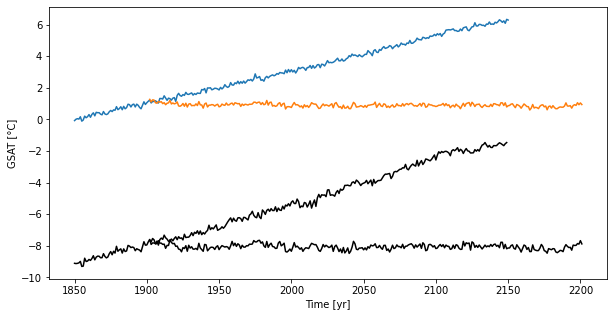

In [188]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ref_CO2 = df_CO2["piControl"].mean()
ref_GSAT = df_GSAT["piControl"].mean()

ax.plot(df_GSAT["year"], df_GSAT["02Kpd"]-ref_GSAT)
ax.plot(df_GSAT["year"], df_GSAT["02Kpd-11"]-ref_GSAT)

ax.plot(ym_tas_11["time"].dt.year, ym_tas_11["tas"].mean(["lat", "lon"])-ref_GSAT-273.15, color="k")
ax.plot(ym_tas["time"].dt.year, ym_tas["tas"].mean(["lat", "lon"])-ref_GSAT-273.15, color="k")

ax.set_xlabel("Time [yr]")
ax.set_ylabel("GSAT [°C]")

#### Question 3: 

Calculating a global mean with a netcdf file is not so straightforward. Ideed, you have to take into account the latitude/longitude grid. This grid is stored in the file _areacella_.
* _Plot the tas map averaged over a certain time period (eg. 1900-1950) as well as the aeracella map. From that infer why your calculation was underestimating the GSAT in the previous question_
* _With that in mind try to recalculate GSAT by using a weighted-mean rather than a simple mean._

__Help:__ Maps can be plotted as follows : 

```
fig, ax = plt.subplots(1, 1, figsize=(10, 5), subplot_kw=dict(projection=ccrs.Robinson(0)))

da.plot(ax=...,
        x=...,
        y=...,
        transform=ccrs.PlateCarree() # This line explains that the data in the dataset are expressed using a regular grid
        ) 
```

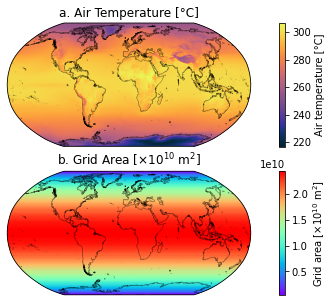

In [189]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), subplot_kw=dict(projection=ccrs.Robinson(0)))

im1 = ym_tas_11["tas"].mean("time").plot(ax=axes[0],
                                   x="lon", 
                                   y="lat",
                                   cmap=cmocean.cm.thermal,
                                   transform=ccrs.PlateCarree(), 
                                   add_colorbar=False)

im2 = areacella["cell_area"].plot(ax=axes[1],
                            x="lon", 
                            y="lat",
                            cmap="rainbow",
                            transform=ccrs.PlateCarree(), 
                            add_colorbar=False)

for axis in axes : 
    axis.set_global()
    axis.coastlines(resolution='10m',
                   linewidth=0.75,zorder=100,alpha=0.35)
    
# Plot aesthetic
axes[0].set_title("a. Air Temperature [°C]")
axes[1].set_title(r"b. Grid Area [${\times}$10$^{10}$ m$^2$]")

cbar1 = fig.colorbar(im1, ax=axes[0], label="Air temperature [°C]")
cbar2 = fig.colorbar(im2, ax=axes[1], label=r"Grid area [${\times}$10$^{10}$ m$^2$]")

In [190]:
wa = areacella["cell_area"]/(areacella["cell_area"].sum(["lat", "lon"]))

In [191]:
wa

<xarray.DataArray 'cell_area' (lat: 128, lon: 256)>
array([[9.28413833e-07, 9.28413833e-07, 9.28413833e-07, ...,
        9.28413833e-07, 9.28413833e-07, 9.28413833e-07],
       [2.04086504e-06, 2.04086504e-06, 2.04086504e-06, ...,
        2.04086504e-06, 2.04086504e-06, 2.04086504e-06],
       [3.20725072e-06, 3.20725072e-06, 3.20725072e-06, ...,
        3.20725072e-06, 3.20725072e-06, 3.20725072e-06],
       ...,
       [3.20725072e-06, 3.20725072e-06, 3.20725072e-06, ...,
        3.20725072e-06, 3.20725072e-06, 3.20725072e-06],
       [2.04086504e-06, 2.04086504e-06, 2.04086504e-06, ...,
        2.04086504e-06, 2.04086504e-06, 2.04086504e-06],
       [9.28413833e-07, 9.28413833e-07, 9.28413833e-07, ...,
        9.28413833e-07, 9.28413833e-07, 9.28413833e-07]])
Coordinates:
  * lon      (lon) float64 0.0 1.406 2.812 4.219 ... 354.4 355.8 357.2 358.6
  * lat      (lat) float64 -88.93 -87.54 -86.14 -84.74 ... 86.14 87.54 88.93

In [193]:
df_GSAT2

,year,CNRM-ESM2-1_piControl_r1i1p2f2,CNRM-ESM2-1_historical_r1i1p2f2,AOESM_02Kpd_CM6_r1_p2_v2,AOESM_02Kpd-11_CM6_r1_p2_v2,AOESM_02Kpd-15_CM6_r1_p2_v2,AOESM_02Kpd-20_CM6_r1_p2_v2,AOESM_02Kpd-25_CM6_r1_p2_v2,AOESM_02Kpd-30_CM6_r1_p2_v2,AOESM_02Kpd-35_CM6_r1_p2_v2,AOESM_02Kpd-40_CM6_r1_p2_v2,AOESM_02Kpd-45_CM6_r1_p2_v2,AOESM_02Kpd-50_CM6_r1_p2_v2,AOESM_esm-up2p0-gwl2p0-50y-dn2p0_CM6_r1_p2,AOESM_esm-up2p0-gwl3p0-50y-dn2p0_CM6_r1_p2,AOESM_esm-up2p0-gwl4p0-50y-dn2p0_CM6_r1_p2,AOESM_esm-up2p0-gwl4p0-50y-dn2p0-gwl2p0_CM6_r1_p2
0,1850,286.74274,286.76633,286.70453,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1851,286.67523,286.81003,286.78897,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1852,286.70120,286.75990,286.82294,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1853,286.52563,286.81418,286.79590,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1854,286.67130,286.62170,286.94452,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
630,2480,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,288.43488
631,2481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,288.54883
632,2482,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,288.53378
633,2483,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,288.42795


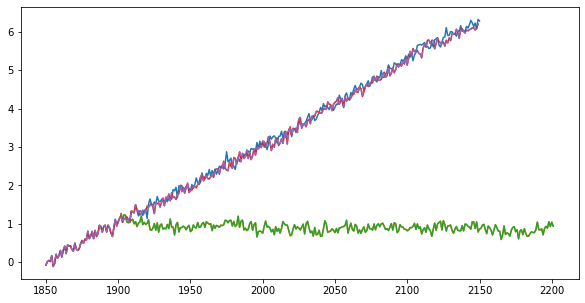

In [199]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

# previous
ax.plot(df_GSAT["year"], df_GSAT["02Kpd"]-ref_GSAT)
ax.plot(df_GSAT["year"], df_GSAT["02Kpd-11"]-ref_GSAT)

# new 
ts_tas_11 = (ym_tas_11["tas"]*wa).sum(["lat", "lon"])
ts_tas = (ym_tas["tas"]*wa).sum(["lat", "lon"])
year =  ym_tas_11["time"].dt.year              

ax.plot(ym_tas_11["time"].dt.year, ts_tas_11-273.15-ref_GSAT)
ax.plot(ym_tas["time"].dt.year, ts_tas-273.15-ref_GSAT)

ax.plot(df_GSAT2["year"], df_GSAT2["AOESM_02Kpd_CM6_r1_p2_v2"]-273.15-ref_GSAT, ls='--')


# ax.set_global()
# ax.coastlines(resolution='10m',
#                linewidth=0.75,zorder=100,alpha=0.35)
    
# # Plot aesthetic
# ax.set_title("Grid weight [-]")

# cbar1 = fig.colorbar(im1, ax=ax, label="Grid weight [-]")


<a id="section-1"></a>
## 2. Why a stabilization ?


equilibration entre processus rechauffant et processus refroidissant
plot de Laura gibbs

Faire des histogrammes

<a id="section-1"></a>
## 3. Extremes and temperature distribution changes


<a id="section-1"></a>
## 4. The case of net-negative emissions



Now we want to investigate what wuld happend if we switch to net-negative emissions.